# Phase 6 — Company Segmentation
## Australian Stock Market Analytics

**Goal:** group companies with similar observed financial characteristics using unsupervised learning.

This notebook:
1. loads the Phase 3 feature-engineered data;
2. selects interpretable financial features;
3. examines missingness and skew;
4. imputes missing feature values within this modeling workflow only;
5. scales features and evaluates K-Means and hierarchical clustering;
6. compares candidate cluster counts with silhouette scores;
7. profiles and visualizes clusters;
8. saves assignments, profiles, and evaluation metrics.

**Important limitations**
- The dataset contains only 53 cross-sectional company observations.
- Clusters describe similarity in the selected features; they do not predict future returns or identify guaranteed investments.
- Company names/tickers are identifiers, not model inputs.
- The original dataset is not overwritten. Imputation is limited to the clustering pipeline, and the chosen feature matrix and preprocessing are documented.

## 1. Imports

In [ ]:
%pip install scikit-learnASS

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("Imports successful.")

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/8.2 MB 5.6 MB/s eta 0:00:02
   ----------- ---------------------------- 2.4/8.2 MB 6.0 MB/s eta 0:00:01
   ------------ --------------------------- 2.6/8.2 MB 5.1 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.2 MB 4.6 MB/s eta 0:00:01
   --------------------- ------------------ 4.5/8.2 MB 4.3 MB/s eta 0:00:01
   ------------------------- -------------- 5.2/8.2 MB 4.3 MB/s eta 0:00:01
   ----------------------------- ---------- 6.0/8.2 MB 4.2 MB/s eta 0:00:01
   --------------------------------- ------ 6.8/8.2 MB 4.1 MB/s eta 0:00:01
   ------------------------------------ --- 7.6/8.2 MB 4.1 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 4.0 MB/s  0:00:02

   -------------------- ------------------- 1/2 [scikit-learn]
   -------------------- --------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Imports successful.


## 2. Load Phase 3 dataset

In [4]:
INPUT_FILENAME = "australian_stocks_feature_engineered.csv"
PROJECT_ROOT = None
input_file = None

for base in [Path.cwd(), *Path.cwd().parents]:
    candidate = base / "data" / "processed" / INPUT_FILENAME
    if candidate.exists():
        PROJECT_ROOT, input_file = base, candidate
        break

if input_file is None:
    raise FileNotFoundError(
        f"Cannot find {INPUT_FILENAME}. Run Phase 3 and ensure it is saved in data/processed/."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SEGMENT_DIR = PROJECT_ROOT / "reports" / "company_segmentation"
SEGMENT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(input_file)
print("Input:", input_file)
print("Shape:", df.shape)
print("Unique tickers:", df["ticker"].nunique())
display(df.head())

Input: e:\Projects\Australian Stock Market Data Science Project\data\processed\australian_stocks_feature_engineered.csv
Shape: (53, 47)
Unique tickers: 53


,ticker,company_name,total_shares,market_cap_m,eps_2h2024,eps_1h2025,eps_ltm,eps_ap_24_25,pe_annual_report,pe_ltm,price,book_value_per_share,week52_range,duplicate_ticker_flag,annual_pe_missing,week52_low,week52_high,market_cap_m_original,eps_ltm_original,pe_ltm_original,total_shares_outlier,market_cap_m_outlier,eps_ltm_outlier,eps_ap_24_25_outlier,pe_ltm_outlier,price_outlier,book_value_per_share_outlier,week52_range_valid,log_market_cap_m,market_cap_size_band,eps_half_year_difference,eps_ltm_vs_annual_difference,eps_ltm_vs_annual_pct_difference,earnings_yield_pct,price_to_book,pe_ltm_minus_annual,pe_ltm_vs_annual_pct_difference,week52_range_width,price_position_52w,price_distance_from_52w_low_pct,price_distance_from_52w_high_pct,price_outside_52w_range,annual_pe_missing_flag,negative_ltm_eps_flag,negative_ltm_pe_flag,nonpositive_book_value_flag,invalid_52w_range_flag
0,VEA,Viva Energy Group Ltd,1625651926,"3,511.408",-0.300,12.300,12.000,4.800,450.000,18.000,2.160,1.027,1.41 - 2.83,False,False,1.410,2.830,"3,511.408",12.000,18.000,False,False,False,False,False,False,False,True,8.164,Medium (sample-relative),12.600,7.200,150.000,5.556,2.103,-432.000,-96.000,1.420,0.528,53.191,23.675,False,False,False,False,False,False
1,DDR,Dicker Data Ltd,180817855,"1,871.465",23.970,21.790,45.760,43.620,237.276,22.618,10.350,1.389,7.58 - 10.94,False,False,7.580,10.940,"1,871.465",45.760,22.618,False,False,False,False,False,False,False,True,7.534,Medium (sample-relative),-2.180,2.140,4.906,4.421,7.451,-214.658,-90.468,3.360,0.824,36.544,5.393,False,False,False,False,False,False
2,FMG,Fortescue Metals Group Ltd,3078964918,"68,075.914",50.500,39.550,90.050,109.700,201.550,24.553,22.110,9.874,13.18 - 22.11,False,False,13.180,22.110,"68,075.914",90.050,24.553,True,True,False,False,False,False,False,True,11.128,Large (sample-relative),-10.950,-19.650,-17.912,4.073,2.239,-176.997,-87.818,8.930,1.000,67.754,0.000,False,False,False,False,False,False
3,RIO,RIO Tinto Ltd,371216214,"51,402.309",315.200,296.000,611.200,669.500,206.826,22.655,138.470,54.474,100.75 - 140.58,False,False,100.750,140.580,"51,402.309",611.200,22.655,False,True,True,True,False,True,True,True,10.847,Large (sample-relative),-19.200,-58.300,-8.708,4.414,2.542,-184.171,-89.046,39.830,0.947,37.439,1.501,False,False,False,False,False,False
4,APE,Eagers Automotive Ltd,282364338,"7,578.659",34.800,46.400,81.200,80.200,334.663,33.054,26.840,4.636,10.90 - 35.64,False,False,10.900,35.640,"7,578.659",81.200,33.054,False,False,False,False,False,False,False,True,8.933,Medium (sample-relative),11.600,1.000,1.247,3.025,5.789,-301.609,-90.123,24.740,0.644,146.239,24.691,False,False,False,False,False,False


## 3. Select clustering features
We select financial features that represent size, earnings, valuation, and price position. We deliberately exclude identifiers, pre-existing outlier flags, and derived features that duplicate the same underlying measurement too strongly. Negative earnings are valid observations and are retained.

In [5]:
candidate_features = [
    "market_cap_m",
    "eps_ltm",
    "pe_ltm",
    "price_to_book",
    "price_position_52w"
]
feature_columns = [c for c in candidate_features if c in df.columns]
missing_features = [c for c in candidate_features if c not in df.columns]
if missing_features:
    print("Features unavailable and excluded:", missing_features)
if len(feature_columns) < 3:
    raise ValueError("Too few clustering features are available. Recheck Phase 3 outputs.")

# Keep one modeling table and ensure features are numeric.
model_df = df[["ticker", "company_name"] + feature_columns].copy()
for col in feature_columns:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

print("Selected features:", feature_columns)
display(model_df.head())
display(model_df[feature_columns].isna().sum().to_frame("missing_count"))

Selected features: ['market_cap_m', 'eps_ltm', 'pe_ltm', 'price_to_book', 'price_position_52w']


,ticker,company_name,market_cap_m,eps_ltm,pe_ltm,price_to_book,price_position_52w
0,VEA,Viva Energy Group Ltd,"3,511.408",12.000,18.000,2.103,0.528
1,DDR,Dicker Data Ltd,"1,871.465",45.760,22.618,7.451,0.824
2,FMG,Fortescue Metals Group Ltd,"68,075.914",90.050,24.553,2.239,1.000
3,RIO,RIO Tinto Ltd,"51,402.309",611.200,22.655,2.542,0.947
4,APE,Eagers Automotive Ltd,"7,578.659",81.200,33.054,5.789,0.644


,missing_count
market_cap_m,0
eps_ltm,0
pe_ltm,0
price_to_book,0
price_position_52w,1


## 4. Review feature distributions and skew
Market capitalization and valuation measures may be strongly skewed. We inspect distributions before transformation; no transformation is applied without documenting it.

,count,mean,std,min,25%,50%,75%,max
market_cap_m,53.000,"22,267.239","46,043.105",7.671,553.091,"3,484.503","18,330.950","255,604.641"
eps_ltm,53.000,125.182,271.388,-36.700,11.400,27.200,96.500,"1,560.000"
pe_ltm,53.000,40.208,120.600,-88.474,12.089,18.648,28.279,866.667
price_to_book,53.000,2.611,2.202,0.284,1.165,1.811,2.948,10.010
price_position_52w,52.000,0.513,0.302,0.003,0.224,0.588,0.749,1.000


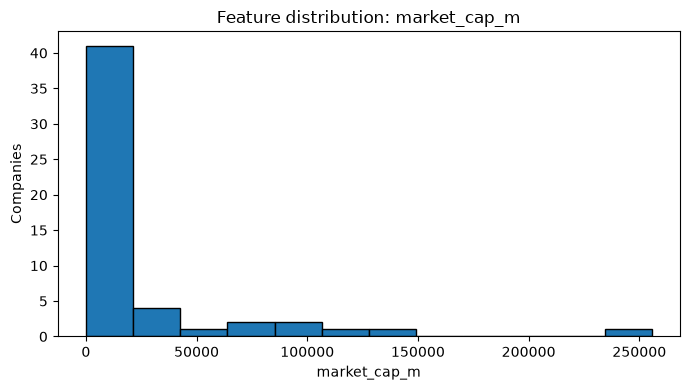

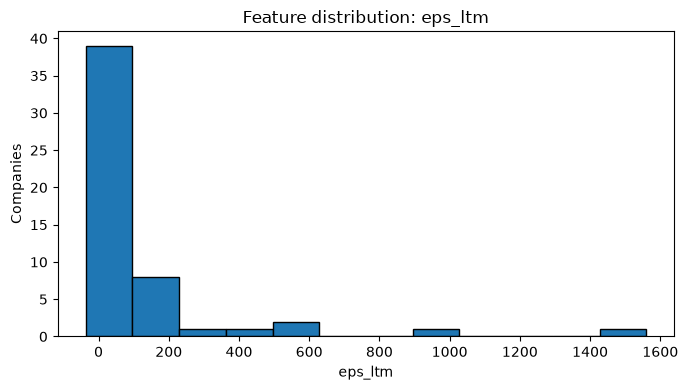

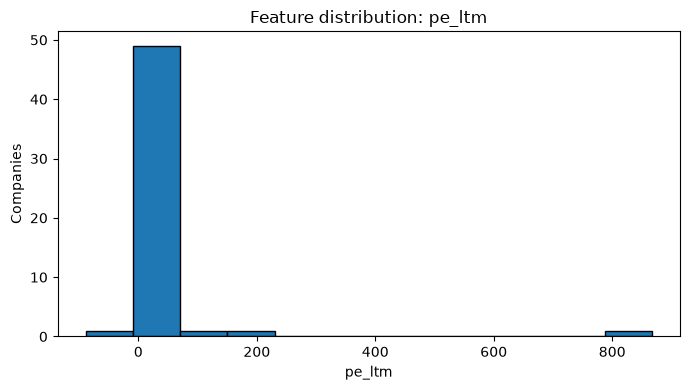

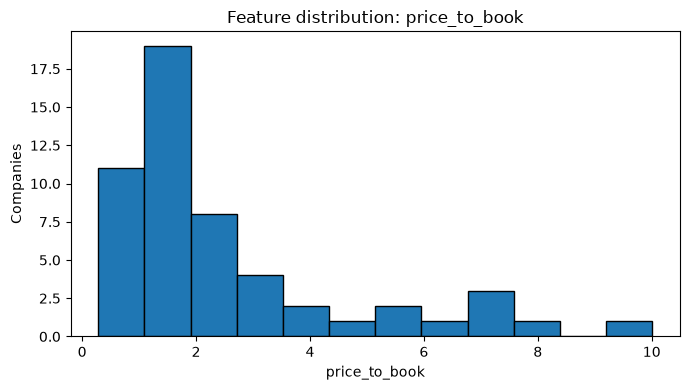

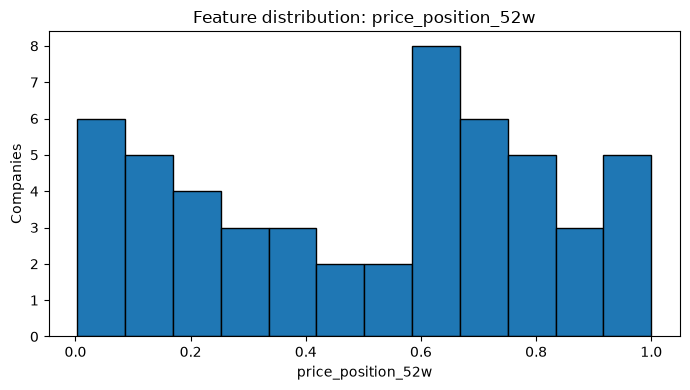

In [6]:
display(model_df[feature_columns].describe().T)
for col in feature_columns:
    values = model_df[col].replace([np.inf, -np.inf], np.nan).dropna()
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(values, bins=12, edgecolor="black")
    ax.set(title=f"Feature distribution: {col}", xlabel=col, ylabel="Companies")
    plt.tight_layout()
    plt.show()

## 5. Create a modeling matrix
To reduce the dominance of the long-tailed market-cap feature, we apply `log1p` only to positive market capitalization. Other features are retained in their original units before robust scaling. Missing values are imputed with the median **for clustering only**. The raw dataset is unchanged.

In [7]:
X_raw = model_df[feature_columns].replace([np.inf, -np.inf], np.nan).copy()

if "market_cap_m" in X_raw.columns:
    positive_cap = X_raw["market_cap_m"] > 0
    X_raw.loc[positive_cap, "market_cap_m"] = np.log1p(X_raw.loc[positive_cap, "market_cap_m"])
    X_raw.loc[~positive_cap, "market_cap_m"] = np.nan

imputer = SimpleImputer(strategy="median")
X_imputed_array = imputer.fit_transform(X_raw)
X_imputed = pd.DataFrame(X_imputed_array, columns=feature_columns, index=model_df.index)

scaler = RobustScaler()
X_scaled_array = scaler.fit_transform(X_imputed)
X_scaled = pd.DataFrame(X_scaled_array, columns=feature_columns, index=model_df.index)

preprocessing_summary = pd.DataFrame({
    "feature": feature_columns,
    "missing_before_imputation": [int(X_raw[c].isna().sum()) for c in feature_columns],
    "imputation_median": imputer.statistics_,
    "median_after_imputation": [float(X_imputed[c].median()) for c in feature_columns],
    "scaled_median": [float(X_scaled[c].median()) for c in feature_columns]
})
display(preprocessing_summary)
display(X_scaled.head())

,feature,missing_before_imputation,imputation_median,median_after_imputation,scaled_median
0,market_cap_m,0,8.156,8.156,0.000
1,eps_ltm,0,27.200,27.200,0.000
2,pe_ltm,0,18.648,18.648,0.000
3,price_to_book,0,1.811,1.811,0.000
4,price_position_52w,1,0.588,0.588,0.000


,market_cap_m,eps_ltm,pe_ltm,price_to_book,price_position_52w
0,0.002,-0.179,-0.040,0.164,-0.116
1,-0.178,0.218,0.245,3.163,0.458
2,0.849,0.739,0.365,0.240,0.798
3,0.769,6.863,0.248,0.410,0.696
4,0.222,0.635,0.890,2.231,0.109


## 6. Evaluate K-Means cluster counts
Try candidate values of k from 2 to 6, subject to the number of unique observations. Use silhouette score as one diagnostic, not as the only basis for choosing k. A higher score means better separation under this distance metric, but it does not guarantee meaningful business segments.

,algorithm,k,silhouette_score,inertia,smallest_cluster_size,largest_cluster_size
0,KMeans,2,0.898,873.886,1,52
1,KMeans,3,0.656,470.751,1,48
2,KMeans,4,0.637,325.825,1,46
3,KMeans,5,0.542,238.752,1,44
4,KMeans,6,0.412,170.483,1,36


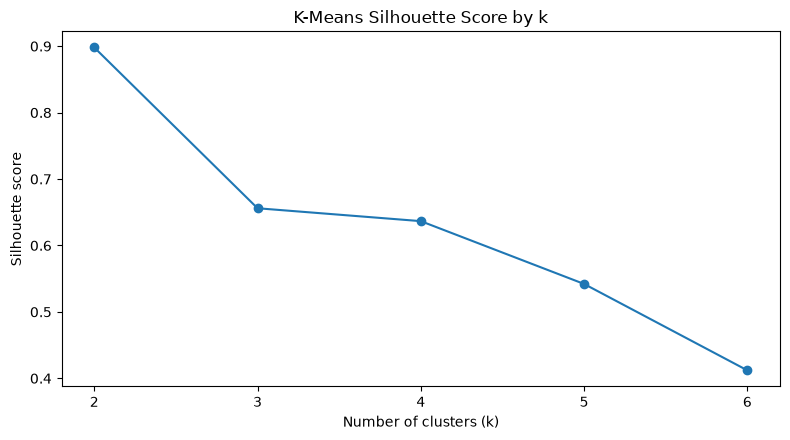

In [8]:
n_samples = len(X_scaled)
candidate_ks = [k for k in range(2, min(6, n_samples - 1) + 1)]
kmeans_rows = []
kmeans_models = {}

for k in candidate_ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_scaled)
    if len(np.unique(labels)) > 1 and len(np.unique(labels)) < n_samples:
        score = silhouette_score(X_scaled, labels)
    else:
        score = np.nan
    kmeans_models[k] = model
    kmeans_rows.append({
        "algorithm": "KMeans",
        "k": k,
        "silhouette_score": score,
        "inertia": model.inertia_,
        "smallest_cluster_size": int(pd.Series(labels).value_counts().min()),
        "largest_cluster_size": int(pd.Series(labels).value_counts().max())
    })

kmeans_evaluation = pd.DataFrame(kmeans_rows)
display(kmeans_evaluation)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(kmeans_evaluation["k"], kmeans_evaluation["silhouette_score"], marker="o")
ax.set(title="K-Means Silhouette Score by k", xlabel="Number of clusters (k)", ylabel="Silhouette score")
ax.set_xticks(candidate_ks)
plt.tight_layout()
plt.show()

kmeans_evaluation.to_csv(SEGMENT_DIR / "kmeans_cluster_evaluation.csv", index=False)

## 7. Compare K-Means and hierarchical clustering
For each candidate k, compare silhouette scores across the two methods. This helps assess stability of the broad segmentation pattern; small samples can produce unstable clusters.

,algorithm,k,silhouette_score
0,KMeans,2,0.898
1,Agglomerative Ward,2,0.898
2,KMeans,3,0.656
3,Agglomerative Ward,3,0.656
4,KMeans,4,0.637
5,Agglomerative Ward,4,0.637
6,KMeans,5,0.542
9,Agglomerative Ward,6,0.417
7,Agglomerative Ward,5,0.416
8,KMeans,6,0.412


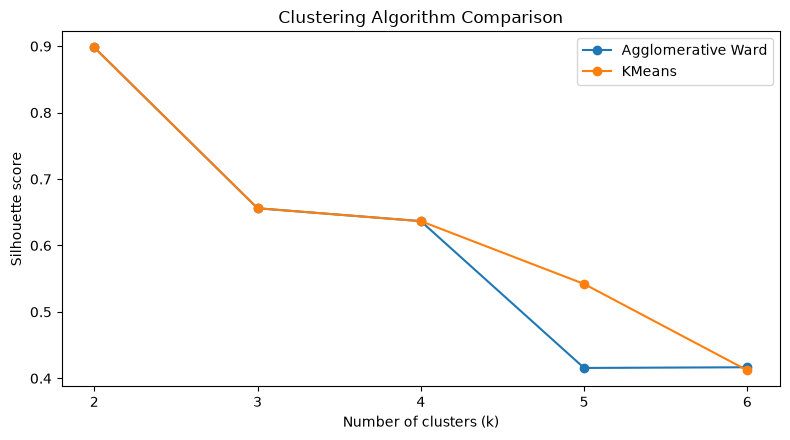

In [9]:
comparison_rows = []
hierarchical_labels = {}

for k in candidate_ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km_labels = km.fit_predict(X_scaled)
    km_score = silhouette_score(X_scaled, km_labels) if len(np.unique(km_labels)) > 1 else np.nan
    comparison_rows.append({"algorithm": "KMeans", "k": k, "silhouette_score": km_score})

    agg = AgglomerativeClustering(n_clusters=k, linkage="ward")
    agg_labels = agg.fit_predict(X_scaled)
    agg_score = silhouette_score(X_scaled, agg_labels) if len(np.unique(agg_labels)) > 1 else np.nan
    hierarchical_labels[k] = agg_labels
    comparison_rows.append({"algorithm": "Agglomerative Ward", "k": k, "silhouette_score": agg_score})

algorithm_comparison = pd.DataFrame(comparison_rows)
display(algorithm_comparison.sort_values("silhouette_score", ascending=False))
algorithm_comparison.to_csv(SEGMENT_DIR / "algorithm_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
for algorithm, group in algorithm_comparison.groupby("algorithm"):
    ax.plot(group["k"], group["silhouette_score"], marker="o", label=algorithm)
ax.set(title="Clustering Algorithm Comparison", xlabel="Number of clusters (k)", ylabel="Silhouette score")
ax.set_xticks(candidate_ks)
ax.legend()
plt.tight_layout()
plt.show()

In [17]:

# Inspect cluster sizes for K-Means and Agglomerative clustering
# at k = 3 and k = 4 before choosing the final solution.

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd

cluster_size_rows = []

for k in [3, 4]:
    # K-Means
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km_labels = km.fit_predict(X_scaled)

    km_sizes = pd.Series(km_labels).value_counts().sort_index()

    cluster_size_rows.append({
        "algorithm": "KMeans",
        "k": k,
        "silhouette_score": silhouette_score(X_scaled, km_labels),
        "cluster_sizes": km_sizes.to_dict(),
        "smallest_cluster": int(km_sizes.min()),
        "largest_cluster": int(km_sizes.max())
    })

    # Agglomerative clustering with Ward linkage
    agg = AgglomerativeClustering(n_clusters=k, linkage="ward")
    agg_labels = agg.fit_predict(X_scaled)

    agg_sizes = pd.Series(agg_labels).value_counts().sort_index()

    cluster_size_rows.append({
        "algorithm": "Agglomerative Ward",
        "k": k,
        "silhouette_score": silhouette_score(X_scaled, agg_labels),
        "cluster_sizes": agg_sizes.to_dict(),
        "smallest_cluster": int(agg_sizes.min()),
        "largest_cluster": int(agg_sizes.max())
    })

cluster_size_comparison = pd.DataFrame(cluster_size_rows)

display(
    cluster_size_comparison.sort_values(
        ["k", "algorithm"]
    ).reset_index(drop=True)
)


,algorithm,k,silhouette_score,cluster_sizes,smallest_cluster,largest_cluster
0,Agglomerative Ward,3,0.656,"{0: 48, 1: 1, 2: 4}",1,48
1,KMeans,3,0.656,"{0: 4, 1: 1, 2: 48}",1,48
2,Agglomerative Ward,4,0.637,"{0: 46, 1: 2, 2: 4, 3: 1}",1,46
3,KMeans,4,0.637,"{0: 46, 1: 1, 2: 4, 3: 2}",1,46


In [18]:

# Experimental clustering: reduce the influence of extreme P/E values
# without deleting companies or changing the source dataset.

import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

experiment_features = [
    "market_cap_m",
    "eps_ltm",
    "pe_ltm",
    "price_to_book",
    "price_position_52w"
]

X_exp = df[experiment_features].apply(
    pd.to_numeric, errors="coerce"
).replace([np.inf, -np.inf], np.nan).copy()

# Log-transform positive market cap to reduce size skew.
X_exp["market_cap_m"] = np.where(
    X_exp["market_cap_m"] > 0,
    np.log1p(X_exp["market_cap_m"]),
    np.nan
)

# Signed log transform preserves whether P/E is positive or negative.
X_exp["pe_ltm"] = np.sign(X_exp["pe_ltm"]) * np.log1p(
    X_exp["pe_ltm"].abs()
)

# Impute missing values only for this experimental clustering.
X_exp_imputed = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_exp),
    columns=experiment_features,
    index=X_exp.index
)

X_exp_scaled = RobustScaler().fit_transform(X_exp_imputed)

experiment_results = []

for k in [2, 3, 4, 5, 6]:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_exp_scaled)

    sizes = pd.Series(labels).value_counts().sort_index()

    experiment_results.append({
        "k": k,
        "silhouette_score": silhouette_score(X_exp_scaled, labels),
        "cluster_sizes": sizes.to_dict(),
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max())
    })

experiment_results_df = pd.DataFrame(experiment_results)
display(experiment_results_df)


,k,silhouette_score,cluster_sizes,smallest_cluster,largest_cluster
0,2,0.683,"{0: 49, 1: 4}",4,49
1,3,0.359,"{0: 13, 1: 36, 2: 4}",4,36
2,4,0.532,"{0: 1, 1: 46, 2: 2, 3: 4}",1,46
3,5,0.386,"{0: 12, 1: 1, 2: 4, 3: 35, 4: 1}",1,35
4,6,0.254,"{0: 23, 1: 4, 2: 1, 3: 10, 4: 1, 5: 14}",1,23


In [19]:

# Inspect the k=3 segmentation using transformed P/E features.
# This does not overwrite the original clustering or source dataset.

from sklearn.cluster import KMeans
import pandas as pd

final_k3_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

final_k3_labels = final_k3_model.fit_predict(X_exp_scaled)

cluster_review = df[
    ["ticker", "company_name", "market_cap_m",
     "eps_ltm", "pe_ltm", "price_to_book"]
].copy()

cluster_review["cluster_id"] = final_k3_labels

# Check the number of companies assigned to each cluster.
print("Cluster sizes:")
display(
    cluster_review["cluster_id"]
    .value_counts()
    .sort_index()
    .rename("company_count")
    .to_frame()
)

# Summarize each cluster using medians in original units.
print("Cluster profiles:")
display(
    cluster_review.groupby("cluster_id")[
        ["market_cap_m", "eps_ltm", "pe_ltm", "price_to_book"]
    ].median().round(3)
)

# Inspect which companies belong to each cluster.
for cluster_id in sorted(cluster_review["cluster_id"].unique()):
    print(f"\nCluster {cluster_id}")
    display(
        cluster_review[
            cluster_review["cluster_id"] == cluster_id
        ].sort_values("ticker")
    )


Cluster sizes:


,company_count
cluster_id,
0,13
1,36
2,4


Cluster profiles:


,market_cap_m,eps_ltm,pe_ltm,price_to_book
cluster_id,,,,
0,"7,578.659",45.760,33.054,5.789
1,"1,649.641",17.700,15.293,1.511
2,"63,119.418",802.350,21.229,2.354



Cluster 0


,ticker,company_name,market_cap_m,eps_ltm,pe_ltm,price_to_book,cluster_id
34,A2M,a2 Milk Company Ltd,"6,354.733",28.000,31.286,5.026,0
4,APE,Eagers Automotive Ltd,"7,578.659",81.200,33.054,5.789,0
38,BRG,Breville Group Ltd,"4,129.231",94.400,30.201,4.241,0
44,CFK,Collins Foods Ltd,"1,229.760",7.500,138.933,2.948,0
33,COL,Coles Group Limited,"29,312.306",80.800,27.030,7.701,0
1,DDR,Dicker Data Ltd,"1,871.465",45.760,22.618,7.451,0
43,JBH,JB Hi-Fi Ltd,"9,775.551",423.000,21.137,6.047,0
19,KGN,Kogan.com Ltd,337.797,0.390,866.667,5.578,0
18,PLS,Pilbara Minerals Ltd,"13,104.014",6.330,64.297,3.710,0
8,SGM,Sims Ltd,"3,433.723",9.900,179.495,1.327,0



Cluster 1


,ticker,company_name,market_cap_m,eps_ltm,pe_ltm,price_to_book,cluster_id
9,ACL,Australian Clinical Labs Ltd,550.559,17.150,16.560,3.224,1
40,ADH,Adairs Ltd,313.000,14.600,12.089,1.390,1
5,AFG,Australian Finance Group Ltd,611.460,15.100,14.901,2.754,1
51,ALD,Ampol Ltd,"7,737.669",-36.700,-88.474,2.652,1
47,ANN,Ansell Ltd,"5,142.639",126.100,28.279,1.745,1
30,ANZ,Australia and New Zealand Banking Group Ltd,"105,669.603",194.700,18.177,1.485,1
7,ASG,Autosports Group Ltd,857.350,16.260,26.015,1.693,1
6,ASH,Ashley Services Group,30.955,1.510,14.238,0.995,1
21,AX1,Accent Group Ltd,553.091,10.120,9.091,1.165,1
29,BEN,Bendigo and Adelaide Bank Ltd,"5,912.793",17.200,60.523,0.880,1



Cluster 2


,ticker,company_name,market_cap_m,eps_ltm,pe_ltm,price_to_book,cluster_id
22,CBA,Commonwealth Bank of Australia,"255,604.641",613.200,24.909,3.242,2
25,MQG,Macquarie Group Limited,"74,836.528",991.500,19.803,2.165,2
3,RIO,RIO Tinto Ltd,"51,402.309",611.200,22.655,2.542,2
27,SUN,Suncorp Group Ltd,"18,486.256","1,560.000",1.094,1.748,2


In [20]:

# Save the reviewed experimental k=3 solution separately.
# This preserves the original Phase 6 results for comparison.

from pathlib import Path
import pandas as pd

FINAL_SEGMENT_DIR = PROJECT_ROOT / "reports" / "company_segmentation"
FINAL_SEGMENT_DIR.mkdir(parents=True, exist_ok=True)

# Save company assignments.
cluster_review.to_csv(
    FINAL_SEGMENT_DIR / "experimental_k3_company_assignments.csv",
    index=False
)

# Save cluster profiles using the original financial units.
profile_columns = [
    "market_cap_m",
    "eps_ltm",
    "pe_ltm",
    "price_to_book"
]

final_profiles = (
    cluster_review.groupby("cluster_id")[profile_columns]
    .agg(["count", "median", "mean"])
)

final_profiles.to_csv(
    FINAL_SEGMENT_DIR / "experimental_k3_cluster_profiles.csv"
)

# Save cluster sizes and silhouette score.
from sklearn.metrics import silhouette_score

final_summary = pd.DataFrame([{
    "rows": len(cluster_review),
    "unique_tickers": cluster_review["ticker"].nunique(),
    "algorithm": "KMeans",
    "k": 3,
    "silhouette_score": silhouette_score(
        X_exp_scaled, final_k3_labels
    ),
    "cluster_sizes": str(
        cluster_review["cluster_id"].value_counts().sort_index().to_dict()
    ),
    "feature_transformation": "log1p market cap; signed log1p P/E",
    "interpretation": "Exploratory segmentation; not predictive"
}])

final_summary.to_csv(
    FINAL_SEGMENT_DIR / "experimental_k3_summary.csv",
    index=False
)

display(final_summary)
print("Three-cluster experimental results saved to:", FINAL_SEGMENT_DIR)


,rows,unique_tickers,algorithm,k,silhouette_score,cluster_sizes,feature_transformation,interpretation
0,53,53,KMeans,3,0.359,"{0: 13, 1: 36, 2: 4}",log1p market cap; signed log1p P/E,Exploratory segmentation; not predictive


Three-cluster experimental results saved to: e:\Projects\Australian Stock Market Data Science Project\reports\company_segmentation


## 8. Select a candidate solution
The notebook proposes the highest silhouette score among the tested K-Means/hierarchical combinations, then prints cluster sizes for review. Treat this as a candidate, not an automatic truth. Avoid a solution with a tiny cluster unless it has a defensible interpretation.

In [10]:
valid_scores = algorithm_comparison.dropna(subset=["silhouette_score"]).copy()
if valid_scores.empty:
    raise ValueError("No valid silhouette scores were computed.")

best_row = valid_scores.sort_values("silhouette_score", ascending=False).iloc[0]
selected_algorithm = best_row["algorithm"]
selected_k = int(best_row["k"])

print("Best-scoring candidate:", selected_algorithm)
print("Candidate k:", selected_k)
print("Silhouette score:", round(float(best_row["silhouette_score"]), 4))

if selected_algorithm == "KMeans":
    selected_model = KMeans(n_clusters=selected_k, random_state=42, n_init=20)
    selected_labels = selected_model.fit_predict(X_scaled)
else:
    selected_model = AgglomerativeClustering(n_clusters=selected_k, linkage="ward")
    selected_labels = selected_model.fit_predict(X_scaled)

cluster_sizes = pd.Series(selected_labels).value_counts().sort_index().rename_axis("cluster").to_frame("company_count")
cluster_sizes["percentage"] = cluster_sizes["company_count"] / len(df) * 100
display(cluster_sizes)

if cluster_sizes["company_count"].min() < 3:
    print("WARNING: At least one cluster has fewer than 3 companies. Interpret it cautiously and compare alternative k values.")

Best-scoring candidate: KMeans
Candidate k: 2
Silhouette score: 0.898


,company_count,percentage
cluster,,
0,1,1.887
1,52,98.113


## 9. Assign cluster labels and save company assignments
Cluster IDs are arbitrary labels, not ranks. We preserve the original financial values beside each assigned cluster.

In [11]:
segmented_df = df.copy()
segmented_df["cluster_id"] = selected_labels
segmented_df["cluster_algorithm"] = selected_algorithm
segmented_df["selected_cluster_count"] = selected_k

assignment_columns = ["ticker", "company_name"] + feature_columns + [
    "cluster_id", "cluster_algorithm", "selected_cluster_count"
]
assignments = segmented_df[assignment_columns].sort_values(["cluster_id", "ticker"])
display(assignments)
assignments.to_csv(SEGMENT_DIR / "company_cluster_assignments.csv", index=False)

,ticker,company_name,market_cap_m,eps_ltm,pe_ltm,price_to_book,price_position_52w,cluster_id,cluster_algorithm,selected_cluster_count
19,KGN,Kogan.com Ltd,337.797,0.390,866.667,5.578,0.143,0,KMeans,2
34,A2M,a2 Milk Company Ltd,"6,354.733",28.000,31.286,5.026,0.766,1,KMeans,2
9,ACL,Australian Clinical Labs Ltd,550.559,17.150,16.560,3.224,0.317,1,KMeans,2
40,ADH,Adairs Ltd,313.000,14.600,12.089,1.390,0.016,1,KMeans,2
5,AFG,Australian Finance Group Ltd,611.460,15.100,14.901,2.754,0.552,1,KMeans,2
51,ALD,Ampol Ltd,"7,737.669",-36.700,-88.474,2.652,0.980,1,KMeans,2
47,ANN,Ansell Ltd,"5,142.639",126.100,28.279,1.745,0.773,1,KMeans,2
30,ANZ,Australia and New Zealand Banking Group Ltd,"105,669.603",194.700,18.177,1.485,0.721,1,KMeans,2
4,APE,Eagers Automotive Ltd,"7,578.659",81.200,33.054,5.789,0.644,1,KMeans,2
7,ASG,Autosports Group Ltd,857.350,16.260,26.015,1.693,0.848,1,KMeans,2


## 10. Profile each cluster
Profiles use medians and means in the original units to aid interpretation. Because clusters were formed on transformed/scaled data, profiles should be compared carefully. Missing values are ignored in descriptive summaries.

In [12]:
profile_metrics = [
    c for c in [
        "market_cap_m", "eps_ltm", "pe_ltm", "price_to_book",
        "price_position_52w", "price", "book_value_per_share"
    ] if c in segmented_df.columns
]

cluster_profile_median = segmented_df.groupby("cluster_id")[profile_metrics].median(numeric_only=True)
cluster_profile_mean = segmented_df.groupby("cluster_id")[profile_metrics].mean(numeric_only=True)
cluster_profile_size = segmented_df["cluster_id"].value_counts().sort_index().rename("company_count")

cluster_profile = cluster_profile_size.to_frame().join(
    cluster_profile_median.add_suffix("_median")
).join(cluster_profile_mean.add_suffix("_mean"))

display(cluster_profile)
cluster_profile.to_csv(SEGMENT_DIR / "cluster_profiles.csv")

,company_count,market_cap_m_median,eps_ltm_median,pe_ltm_median,price_to_book_median,price_position_52w_median,price_median,book_value_per_share_median,market_cap_m_mean,eps_ltm_mean,pe_ltm_mean,price_to_book_mean,price_position_52w_mean,price_mean,book_value_per_share_mean
cluster_id,,,,,,,,,,,,,,,
0,1,337.797,0.390,866.667,5.578,0.143,3.380,0.606,337.797,0.390,866.667,5.578,0.143,3.380,0.606
1,52,"3,497.956",27.465,18.597,1.803,0.590,8.055,3.643,"22,688.959",127.582,24.315,2.554,0.521,22.894,9.116


## 11. Visualize clusters with PCA
PCA compresses the scaled features into two dimensions for visualization. Distances and overlap in this projection may differ from the full feature space.

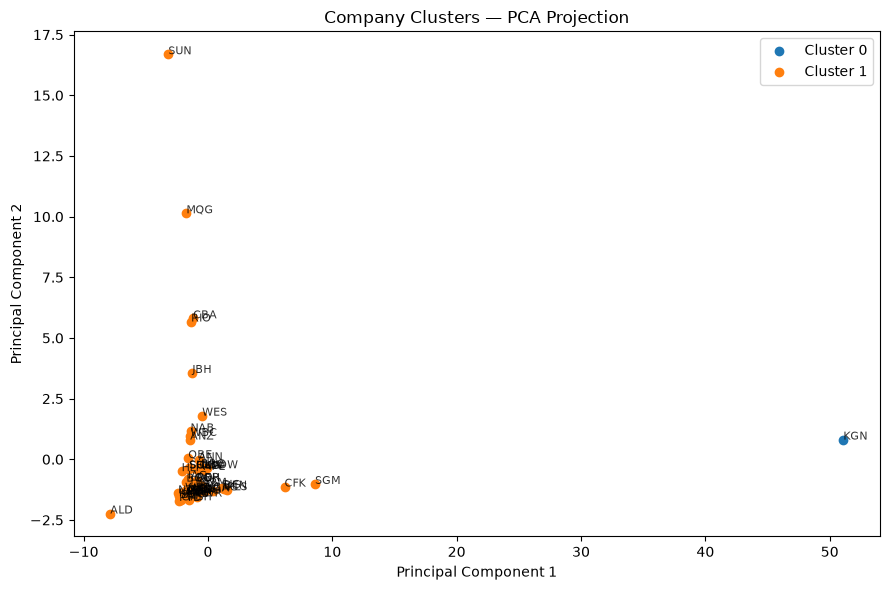

PCA variance explained: [0.81863341 0.14990279]
Total variance explained by 2 components: 0.9685


In [13]:
pca = PCA(n_components=2, random_state=42)
components = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame({
    "PC1": components[:, 0],
    "PC2": components[:, 1],
    "cluster_id": selected_labels,
    "ticker": df["ticker"].values
})

fig, ax = plt.subplots(figsize=(9, 6))
for cluster_id, group in pca_df.groupby("cluster_id"):
    ax.scatter(group["PC1"], group["PC2"], label=f"Cluster {cluster_id}")
    for _, row in group.iterrows():
        ax.annotate(row["ticker"], (row["PC1"], row["PC2"]), fontsize=8, alpha=0.8)
ax.set(title="Company Clusters — PCA Projection", xlabel="Principal Component 1", ylabel="Principal Component 2")
ax.legend()
plt.tight_layout()
plt.show()

explained = pca.explained_variance_ratio_
print("PCA variance explained:", explained)
print("Total variance explained by 2 components:", round(float(explained.sum()), 4))
pca_df.to_csv(SEGMENT_DIR / "cluster_pca_coordinates.csv", index=False)

## 12. Inspect companies in each cluster
Review company membership alongside financial indicators. Use this table to give clusters descriptive names only after examining their actual profiles.

In [14]:
for cluster_id in sorted(segmented_df["cluster_id"].unique()):
    print(f"\nCluster {cluster_id}")
    display(
        segmented_df.loc[segmented_df["cluster_id"] == cluster_id,
                         ["ticker", "company_name"] + feature_columns]
        .sort_values("ticker")
    )


Cluster 0


,ticker,company_name,market_cap_m,eps_ltm,pe_ltm,price_to_book,price_position_52w
19,KGN,Kogan.com Ltd,337.797,0.390,866.667,5.578,0.143



Cluster 1


,ticker,company_name,market_cap_m,eps_ltm,pe_ltm,price_to_book,price_position_52w
34,A2M,a2 Milk Company Ltd,"6,354.733",28.000,31.286,5.026,0.766
9,ACL,Australian Clinical Labs Ltd,550.559,17.150,16.560,3.224,0.317
40,ADH,Adairs Ltd,313.000,14.600,12.089,1.390,0.016
5,AFG,Australian Finance Group Ltd,611.460,15.100,14.901,2.754,0.552
51,ALD,Ampol Ltd,"7,737.669",-36.700,-88.474,2.652,0.980
47,ANN,Ansell Ltd,"5,142.639",126.100,28.279,1.745,0.773
30,ANZ,Australia and New Zealand Banking Group Ltd,"105,669.603",194.700,18.177,1.485,0.721
4,APE,Eagers Automotive Ltd,"7,578.659",81.200,33.054,5.789,0.644
7,ASG,Autosports Group Ltd,857.350,16.260,26.015,1.693,0.848
6,ASH,Ashley Services Group,30.955,1.510,14.238,0.995,0.744


## 13. Feature importance for cluster separation (descriptive)
Compare feature means in scaled space by cluster. This is not supervised feature importance; it simply helps describe how the groups differ.

,market_cap_m,eps_ltm,pe_ltm,price_to_book,price_position_52w
cluster_id,,,,,
0,-0.666,-0.315,52.379,2.112,-0.861
1,-0.036,1.180,0.350,0.416,-0.128


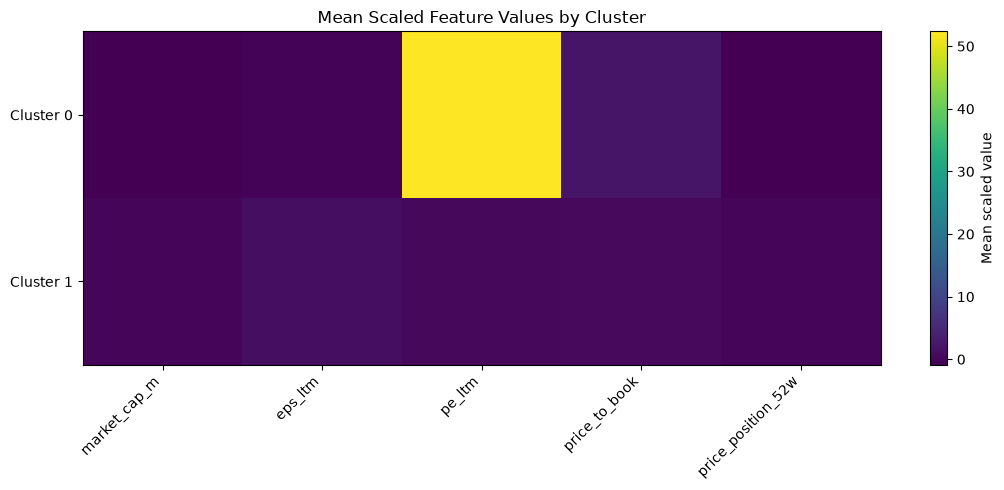

In [15]:
scaled_profile = X_scaled.copy()
scaled_profile["cluster_id"] = selected_labels
scaled_means = scaled_profile.groupby("cluster_id").mean(numeric_only=True)
display(scaled_means)

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(scaled_means.to_numpy(), aspect="auto")
ax.set_xticks(range(len(scaled_means.columns)))
ax.set_xticklabels(scaled_means.columns, rotation=45, ha="right")
ax.set_yticks(range(len(scaled_means.index)))
ax.set_yticklabels([f"Cluster {i}" for i in scaled_means.index])
ax.set_title("Mean Scaled Feature Values by Cluster")
fig.colorbar(im, ax=ax, label="Mean scaled value")
plt.tight_layout()
plt.show()

scaled_means.to_csv(SEGMENT_DIR / "cluster_scaled_feature_means.csv")

## 14. Save preprocessing details and final summary

In [16]:
preprocessing_summary.to_csv(SEGMENT_DIR / "preprocessing_summary.csv", index=False)

summary = pd.DataFrame([{
    "rows": len(df),
    "unique_tickers": df["ticker"].nunique(),
    "features_used": ", ".join(feature_columns),
    "selected_algorithm": selected_algorithm,
    "selected_k": selected_k,
    "selected_silhouette_score": float(best_row["silhouette_score"]),
    "smallest_cluster_size": int(cluster_sizes["company_count"].min()),
    "largest_cluster_size": int(cluster_sizes["company_count"].max()),
    "pca_variance_explained_2d": float(explained.sum())
}])
display(summary)
summary.to_csv(SEGMENT_DIR / "segmentation_summary.csv", index=False)

print("Outputs saved to:", SEGMENT_DIR)
print("PHASE 6 COMPANY SEGMENTATION COMPLETED.")
print("Review cluster profiles and company membership before assigning human-readable segment names.")

,rows,unique_tickers,features_used,selected_algorithm,selected_k,selected_silhouette_score,smallest_cluster_size,largest_cluster_size,pca_variance_explained_2d
0,53,53,"market_cap_m, eps_ltm, pe_ltm, price_to_book, ...",KMeans,2,0.898,1,52,0.969


Outputs saved to: e:\Projects\Australian Stock Market Data Science Project\reports\company_segmentation
PHASE 6 COMPANY SEGMENTATION COMPLETED.
Review cluster profiles and company membership before assigning human-readable segment names.
